In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)



In [4]:
df = pd.read_csv("flood_prediction_indonesia.csv")
df

,rainfall_mm,rainfall_3day_mm,river_level_m,humidity,temperature,wind_speed,elevation,dist_river_km,drainage_index,pop_density,latitude,longitude,Year,Month,flood
0,107.4,251.1,3.85,89,29.6,13.4,21.9,0.46,7,4177,0.9831,124.8238,2024,12,1
1,44.0,109.0,3.07,79,31.1,14.6,23.2,2.40,6,2216,1.9677,124.9946,2024,12,0
2,72.5,103.2,2.98,74,28.2,5.3,36.6,1.94,6,18093,3.6575,98.5927,2024,12,1
3,46.6,141.9,3.04,80,27.1,10.3,23.7,1.92,2,22463,3.8686,98.6404,2024,12,0
4,113.8,192.2,4.91,89,29.8,12.5,148.6,2.39,3,6157,-6.9895,107.1741,2024,12,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,22.8,129.3,3.07,81,29.8,6.3,15.2,0.68,5,2198,-2.7162,114.5632,2010,1,1
796,34.9,129.9,3.63,76,31.1,23.4,17.6,0.38,7,5639,-2.9875,104.9761,2010,1,0
797,79.7,110.5,1.40,74,29.0,28.7,3.8,1.47,6,7813,-6.3266,106.6227,2010,1,0
798,17.2,296.9,6.04,74,28.9,7.0,10.4,0.37,5,922,-3.8276,128.4358,2010,1,1


In [5]:
df.shape

(800, 15)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   rainfall_mm       800 non-null    float64
 1   rainfall_3day_mm  800 non-null    float64
 2   river_level_m     800 non-null    float64
 3   humidity          800 non-null    int64  
 4   temperature       800 non-null    float64
 5   wind_speed        800 non-null    float64
 6   elevation         800 non-null    float64
 7   dist_river_km     800 non-null    float64
 8   drainage_index    800 non-null    int64  
 9   pop_density       800 non-null    int64  
 10  latitude          800 non-null    float64
 11  longitude         800 non-null    float64
 12  Year              800 non-null    int64  
 13  Month             800 non-null    int64  
 14  flood             800 non-null    int64  
dtypes: float64(9), int64(6)
memory usage: 93.9 KB


In [7]:
df.describe()

,rainfall_mm,rainfall_3day_mm,river_level_m,humidity,temperature,wind_speed,elevation,dist_river_km,drainage_index,pop_density,latitude,longitude,Year,Month,flood
count,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,51.492625,125.879375,3.484700,76.875000,29.660375,13.285125,90.381125,1.913687,5.335000,5117.911250,-3.197490,113.359909,2016.790000,6.237500,0.362500
std,46.678233,82.805328,1.639681,8.292034,1.854985,7.084395,294.643361,1.571587,2.013167,4880.237863,3.540923,11.605489,4.398304,4.071156,0.481023
min,0.300000,14.900000,0.300000,55.000000,22.800000,2.000000,1.000000,0.050000,1.000000,339.000000,-9.148000,97.903500,2010.000000,1.000000,0.000000
25%,18.400000,64.350000,2.320000,71.000000,28.500000,8.100000,7.600000,0.820000,4.000000,1955.250000,-6.682525,105.187600,2013.000000,2.000000,0.000000
50%,37.550000,106.000000,3.215000,76.000000,29.700000,12.100000,15.800000,1.510000,5.000000,3557.000000,-3.200650,110.412250,2017.000000,5.500000,0.000000
75%,70.700000,167.975000,4.392500,82.000000,30.900000,17.000000,31.700000,2.482500,7.000000,6558.250000,-0.240600,119.168325,2021.000000,11.000000,1.000000
max,386.700000,634.000000,12.000000,100.000000,36.000000,48.900000,2000.000000,9.870000,10.000000,30000.000000,4.317100,141.531100,2024.000000,12.000000,1.000000


In [8]:
df.isnull().sum()

rainfall_mm         0
rainfall_3day_mm    0
river_level_m       0
humidity            0
temperature         0
wind_speed          0
elevation           0
dist_river_km       0
drainage_index      0
pop_density         0
latitude            0
longitude           0
Year                0
Month               0
flood               0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

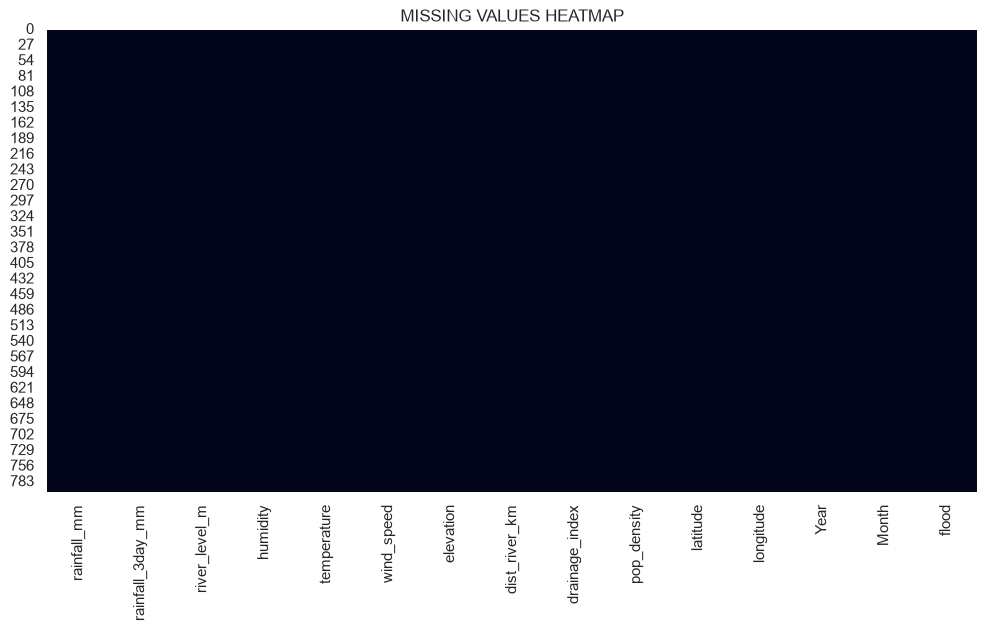

In [10]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=False)
plt.title('MISSING VALUES HEATMAP')
plt.show()

In [11]:
num_cols = df[['rainfall_mm', 'rainfall_3day_mm','river_level_m','elevation','dist_river_km','drainage_index']].columns
num_cols

Index(['rainfall_mm', 'rainfall_3day_mm', 'river_level_m', 'elevation',
       'dist_river_km', 'drainage_index'],
      dtype='str')

In [12]:
for col in num_cols:
  print(f"Uniqeu Values in Columns : {col}")
  print(df[col].unique())
  print("=" * 100)

Uniqeu Values in Columns : rainfall_mm
[1.074e+02 4.400e+01 7.250e+01 4.660e+01 1.138e+02 2.690e+01 9.530e+01
 3.850e+01 1.760e+01 8.220e+01 1.058e+02 1.291e+02 3.430e+01 8.910e+01
 3.520e+01 1.220e+01 4.140e+01 2.300e+00 1.070e+02 3.980e+01 6.560e+01
 5.000e+01 2.150e+01 1.200e+01 7.360e+01 3.810e+01 2.760e+01 1.960e+01
 1.430e+01 1.050e+01 2.000e+01 1.940e+01 1.320e+01 2.640e+01 5.250e+01
 7.580e+01 1.709e+02 7.060e+01 5.210e+01 8.450e+01 7.730e+01 1.021e+02
 1.660e+01 7.740e+01 1.119e+02 2.060e+01 1.750e+01 1.210e+01 1.453e+02
 2.390e+01 1.123e+02 4.320e+01 7.500e+01 1.487e+02 9.230e+01 2.400e+01
 4.080e+01 4.790e+01 2.730e+01 8.260e+01 1.000e+01 2.599e+02 1.500e+01
 9.740e+01 7.000e+00 1.840e+01 6.920e+01 3.400e+01 3.400e+00 2.460e+01
 1.640e+01 5.280e+01 1.860e+01 2.720e+01 2.550e+01 3.100e+01 2.180e+01
 3.900e+00 1.820e+01 2.700e+01 1.100e+00 6.690e+01 4.380e+01 1.020e+02
 5.160e+01 2.334e+02 3.510e+01 1.116e+02 1.442e+02 1.169e+02 8.020e+01
 7.330e+01 4.050e+01 6.290e+01 3.540e+

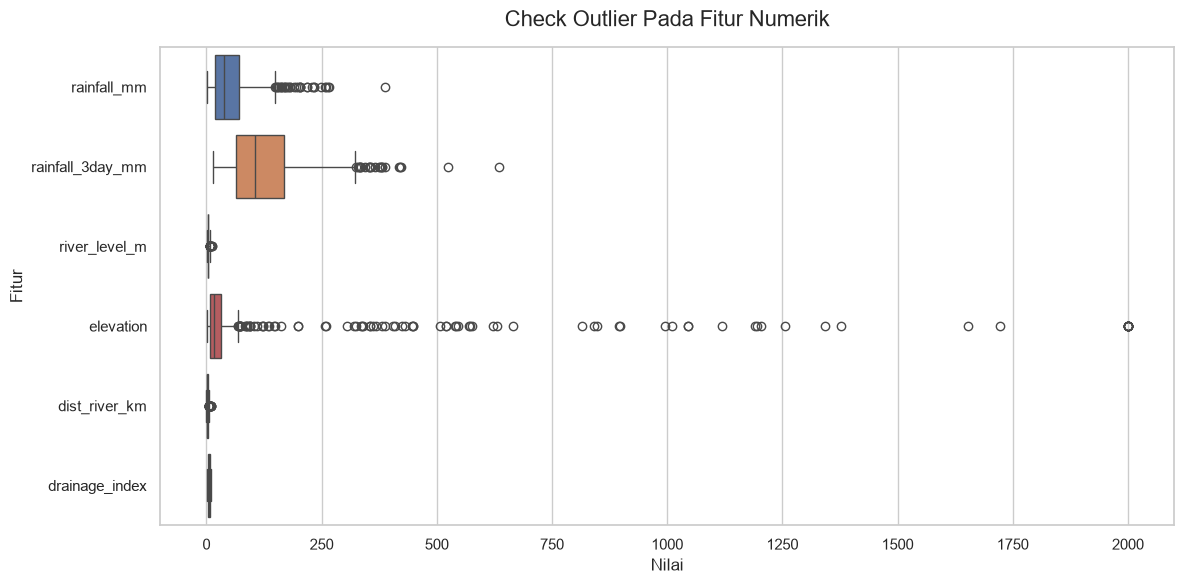

In [13]:
data = num_cols
plt.figure(figsize=(12,6))
sns.boxplot(data=df[data], orient='h')
plt.title("Check Outlier Pada Fitur Numerik", fontsize=16 , pad=15)
plt.xlabel("Nilai" , fontsize=12)
plt.ylabel("Fitur", fontsize=12)

plt.tight_layout()
plt.show()

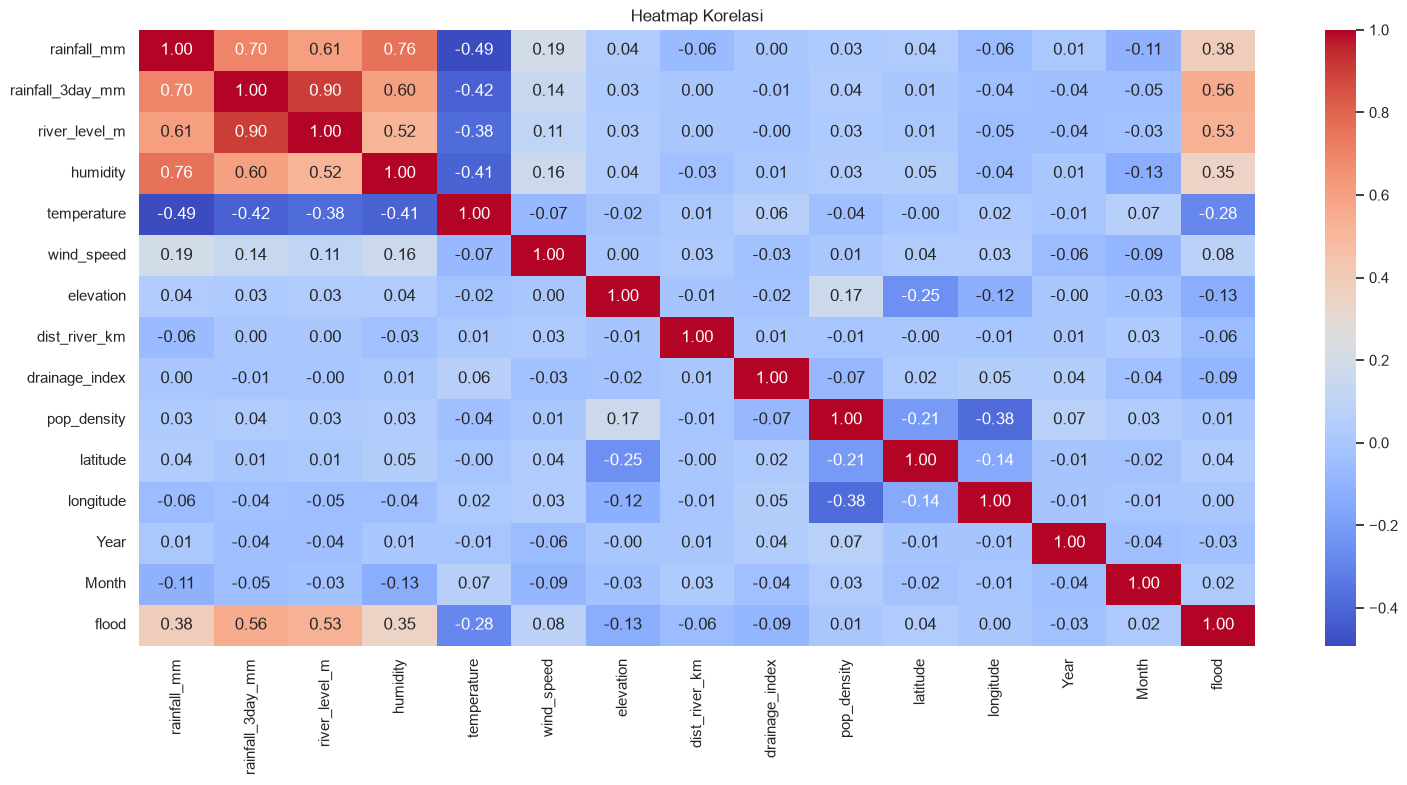

In [14]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(18,8))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Heatmap Korelasi")
plt.show()

In [15]:
for col in data:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  df[col] = np.where(df[col] < lower_bound, lower_bound,
            np.where(df[col] > upper_bound, upper_bound,df[col]))


  print(f"""
Kolom : {col}
Q1 : {Q1}
Q3 : {Q3} 
IQR : {IQR}
lower bound : {lower_bound}
upper bound : {upper_bound}
""")


Kolom : rainfall_mm
Q1 : 18.4
Q3 : 70.7 
IQR : 52.300000000000004
lower bound : -60.050000000000004
upper bound : 149.15


Kolom : rainfall_3day_mm
Q1 : 64.35000000000001
Q3 : 167.975 
IQR : 103.62499999999999
lower bound : -91.08749999999996
upper bound : 323.41249999999997


Kolom : river_level_m
Q1 : 2.32
Q3 : 4.3925 
IQR : 2.0725000000000002
lower bound : -0.7887500000000007
upper bound : 7.501250000000001


Kolom : elevation
Q1 : 7.6
Q3 : 31.7 
IQR : 24.1
lower bound : -28.550000000000004
upper bound : 67.85000000000001


Kolom : dist_river_km
Q1 : 0.82
Q3 : 2.4825 
IQR : 1.6625
lower bound : -1.6737500000000005
upper bound : 4.97625


Kolom : drainage_index
Q1 : 4.0
Q3 : 7.0 
IQR : 3.0
lower bound : -0.5
upper bound : 11.5



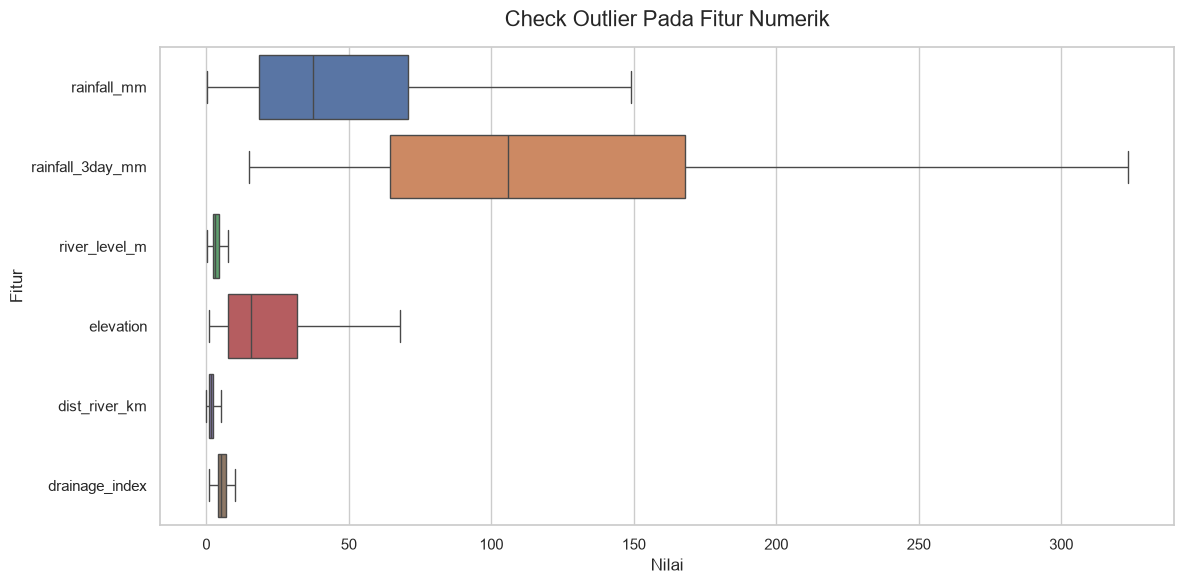

BERIKUT DATA OUTLIER SETELAH DI BUAT LEBIH RAPIH


In [16]:
data = num_cols
plt.figure(figsize=(12,6))
sns.boxplot(data=df[data], orient='h')
plt.title("Check Outlier Pada Fitur Numerik", fontsize=16 , pad=15)
plt.xlabel("Nilai" , fontsize=12)
plt.ylabel("Fitur", fontsize=12)

plt.tight_layout()
plt.show()

print("berikut data outlier setelah di buat lebih rapih".upper())

In [36]:
x = df[num_cols]
y = df['flood']

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"jumlah data train : {X_train.shape}")
print(f"jumlah data test : {X_test.shape}")
print(f"jumlah data train : {y_train.shape}")
print(f"jumlah data test : {y_test.shape}")

jumlah data train : (640, 6)
jumlah data test : (160, 6)
jumlah data train : (640,)
jumlah data test : (160,)


In [38]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num' , StandardScaler(), num_cols),
    ],
    remainder='passthrough'
)

In [20]:
models = {
    'Logistic Regression' : LogisticRegression(),
    'K-Nearest Neighbors' : KNeighborsClassifier(),
    'Support Vector Machine' : SVC(probability=True, random_state=42),
    'Decision Tree' : DecisionTreeClassifier(random_state=42),
    'Random Forest' : RandomForestClassifier(random_state=42)
}

In [39]:
results_list = []

for name , model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:,1] if hasattr(pipeline, "predict_proba") else None

    acc = accuracy_score(y_test,y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.False_

    results_list.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    })

df_results = pd.DataFrame(results_list).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print(df_results)

                    Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
0  Support Vector Machine   0.81250   0.850000  0.586207  0.693878  0.819135
1     Logistic Regression   0.79375   0.804878  0.568966  0.666667  0.865281
2     K-Nearest Neighbors   0.76875   0.733333  0.568966  0.640777  0.799273
3           Random Forest   0.74375   0.688889  0.534483  0.601942  0.838151
4           Decision Tree   0.71250   0.607143  0.586207  0.596491  0.685260


In [22]:
print(df['flood'].value_counts())
print(df['flood'].value_counts(normalize=True) * 100)

flood
0    510
1    290
Name: count, dtype: int64
flood
0    63.75
1    36.25
Name: proportion, dtype: float64


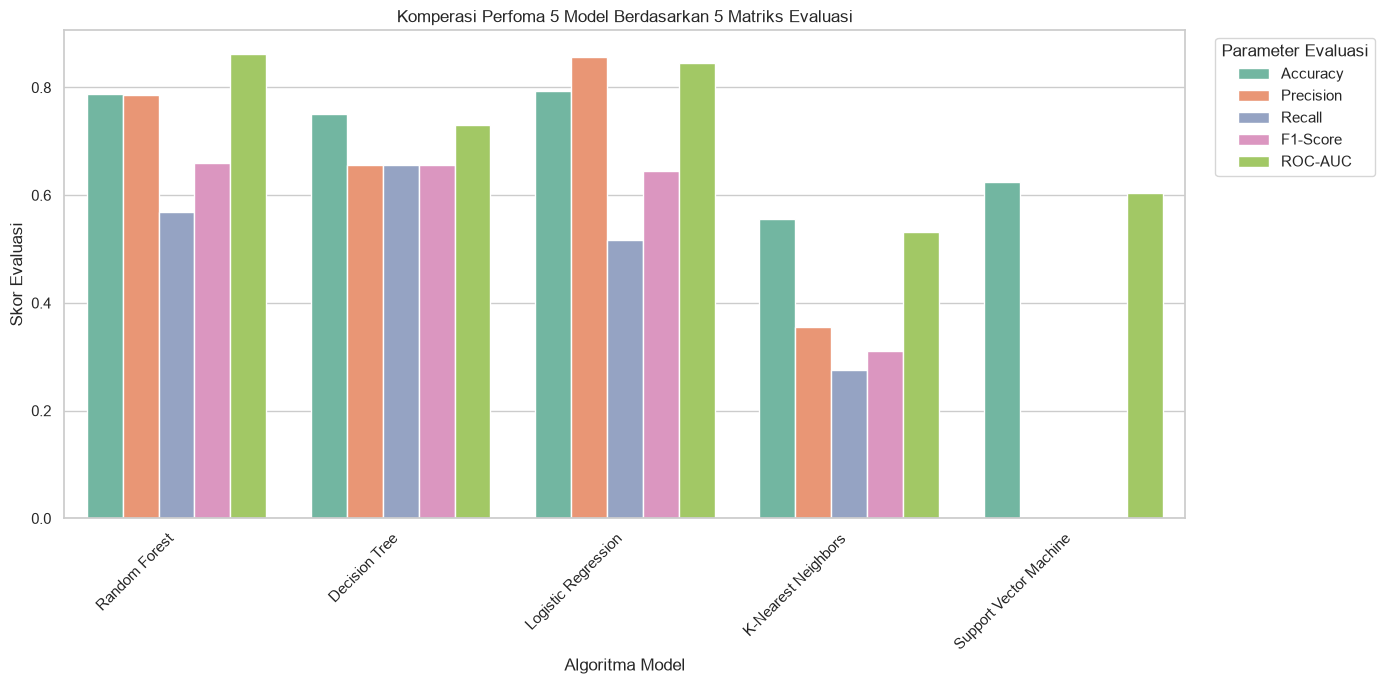

In [23]:
df_melted = df_results.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(14,7))
ax = sns.barplot(data=df_melted, x='Model', y='Score', hue='Metric', palette='Set2')
plt.title("Komperasi Perfoma 5 Model Berdasarkan 5 Matriks Evaluasi")
plt.xlabel("Algoritma Model", fontsize=12)
plt.ylabel("Skor Evaluasi", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Parameter Evaluasi', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [24]:
best_base_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42))
])

In [25]:
param_grid = {
    'classifier__C': [0.00001, 0.0001, 0.001, 0.01, 0.1, 1],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear', 'saga'],
    'classifier__max_iter': [100, 200, 500, ]
}

In [26]:
grid_search = GridSearchCV(
    estimator=best_base_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

=== MEMULAI HYPERPARAMETER TUNING ===
Fitting 5 folds for each of 72 candidates, totalling 360 fits

Hyperparameter Terbaik: {'classifier__C': 1, 'classifier__max_iter': 100, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}
Skor F1 Terbaik saat Cross-Validation: 0.6493

=== CLASSIFICATION REPORT MODEL HASIL TUNING ===
              precision    recall  f1-score   support

           0       0.78      0.89      0.83       102
           1       0.75      0.57      0.65        58

    accuracy                           0.78       160
   macro avg       0.77      0.73      0.74       160
weighted avg       0.77      0.78      0.77       160



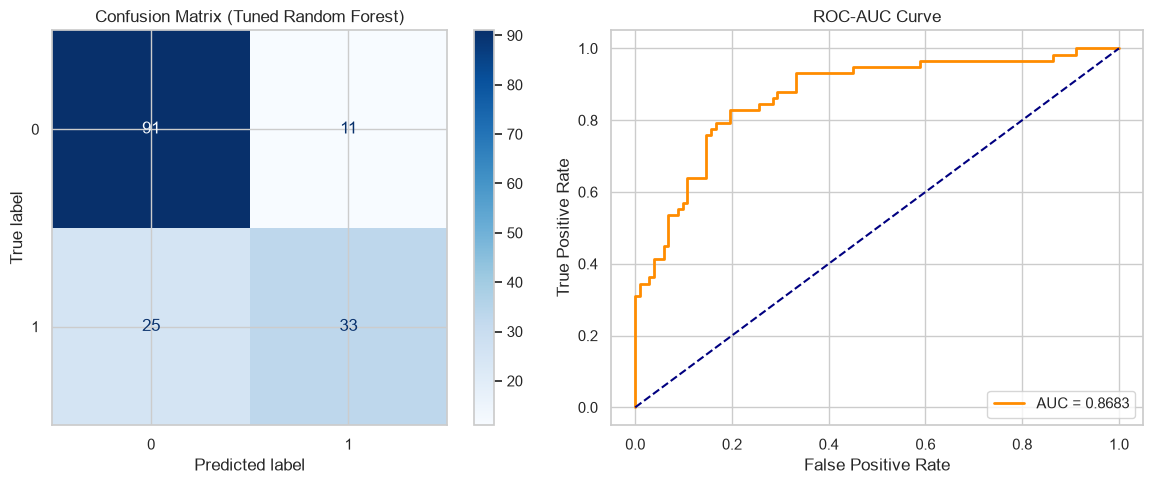

In [27]:
print("=== MEMULAI HYPERPARAMETER TUNING ===")
grid_search.fit(X_train, y_train)

print(f"\nHyperparameter Terbaik: {grid_search.best_params_}")
print(f"Skor F1 Terbaik saat Cross-Validation: {grid_search.best_score_:.4f}")


final_model = grid_search.best_estimator_
y_pred_tuned = final_model.predict(X_test)
y_proba_tuned = final_model.predict_proba(X_test)[:, 1]

print("\n=== CLASSIFICATION REPORT MODEL HASIL TUNING ===")
print(classification_report(y_test, y_pred_tuned))


fig, ax = plt.subplots(1, 2, figsize=(12, 5))


ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned, ax=ax[0], cmap='Blues')
ax[0].set_title('Confusion Matrix (Tuned Random Forest)')


fpr, tpr, _ = roc_curve(y_test, y_proba_tuned)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_proba_tuned):.4f}", color='darkorange', lw=2)
ax[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate')
ax[1].set_title('ROC-AUC Curve')
ax[1].legend(loc='lower right')

plt.tight_layout()
plt.show()